In [48]:
import pandas as pd
from pathlib import Path
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import inspect
import textwrap
import traceback
import astro_prost.helpers as prost_helpers
from scipy.stats import gamma, uniform
from astro_prost import associate_sample
from scipy import stats


In [51]:
with open(Path("Result") / "snia_results.json", "r", encoding="utf-8") as f:
    transientsog = json.load(f)

transientsog = pd.DataFrame(transientsog)

In [53]:
transientsog

,diaObjectId,tns_name,z,catalogue_object_id,tns_prefix,type,ra,decl,absMag,nDiaSources
0,170019717277810735,2026ctw,0.150000,"10000,342494,11570",SN,SN Ia,151.740293,1.927064,NaN,754
1,170028486191218743,2026qrh,0.100000,"10000,81273,866",SN,SN Ia,64.185342,-48.943229,NaN,88
2,170028500610711681,2024xom,0.044167,CGCG036-024,SN,SN Ia,150.746125,2.336469,NaN,165
3,170028510695916335,2025mbp,0.046160,2MASXJ10062208+0109317,SN,SN Ia,151.592617,1.158385,NaN,273
4,170028520834072659,2026fgl,0.164000,WISEAJ095652.35+032811.7,SN,SN Ia,149.218165,3.469919,-16.5385,19
...,...,...,...,...,...,...,...,...,...,...
122,170661828398940941,2025bbx,0.067000,14470795-3930390,SN,SN Ia,221.785403,-39.509297,NaN,3
123,313893021499785278,2026ezw,0.131000,SDSSJ095832.59+011610.2,SN,SN Ia,149.635687,1.269344,NaN,20
124,313932566867476549,2026qrh,0.100000,"10000,81273,866",SN,SN Ia,64.185342,-48.943229,NaN,9
125,313972182793322538,2026fgl,0.164000,WISEAJ095652.35+032811.7,SN,SN Ia,149.218165,3.469919,-16.2020,17


In [54]:
transients = (
    transientsog[["diaObjectId", "tns_name", "ra", "decl"]]
    .rename(columns={"decl": "dec"})
    .dropna()
    .reset_index(drop=True)
    .copy()
)

transients["tns_name"] = transients["tns_name"].astype(str)

print(f"Associating {len(transients)} transients")
display(transients)

Associating 127 transients


,diaObjectId,tns_name,ra,dec
0,170019717277810735,2026ctw,151.740293,1.927064
1,170028486191218743,2026qrh,64.185342,-48.943229
2,170028500610711681,2024xom,150.746125,2.336469
3,170028510695916335,2025mbp,151.592617,1.158385
4,170028520834072659,2026fgl,149.218165,3.469919
...,...,...,...,...
122,170661828398940941,2025bbx,221.785403,-39.509297
123,313893021499785278,2026ezw,149.635687,1.269344
124,313932566867476549,2026qrh,64.185342,-48.943229
125,313972182793322538,2026fgl,149.218165,3.469919


In [55]:
transientsog.columns

Index(['diaObjectId', 'tns_name', 'z', 'catalogue_object_id', 'tns_prefix',
       'type', 'ra', 'decl', 'absMag', 'nDiaSources'],
      dtype='str')

In [ ]:
# Temporary read-only fix without editing helpers.py.
if not getattr(prost_helpers, "_shape_r_copy_patch_applied", False):
    source = textwrap.dedent(
        inspect.getsource(prost_helpers.calc_shape_props_decals)
    )

    old = 'candidate_hosts["shape_r"].values'
    new = 'candidate_hosts["shape_r"].to_numpy(copy=True)'

    if old not in source:
        raise RuntimeError("Expected shape_r code not found.")

    source = source.replace(old, new)
    exec(
        compile(source, "<prost_notebook_patch>", "exec"),
        prost_helpers.__dict__,
    )
    prost_helpers._shape_r_copy_patch_applied = True

# Collect results in memory.
results = []
failed = []

for i in range(len(transients)):
    one_transient = transients.iloc[[i]].copy().reset_index(drop=True)
    name = str(one_transient.iloc[0]["tns_name"])

    try:
        result = associate_sample(
        one_transient,
        catalogs=["decals", "panstarrs", "skymapper"],
        name_col="tns_name",
        coord_cols=("ra", "dec"),
        priors={"offset": uniform(loc=0, scale=10)},
        likes={"offset": gamma(a=0.75)},
        n_samples=1000,  
        parallel=False,
        save=False,
        )
    

        if isinstance(result, Exception):
            raise result

        if not isinstance(result, pd.DataFrame):
            raise TypeError(
                f"Expected DataFrame; got {type(result).__name__}"
            )

        if result.empty:
            raise ValueError("PROST returned an empty DataFrame.")

        results.append(result)
        print(f"{i + 1}/{len(transients)} done: {name}")

    except Exception as exc:
        failed.append({"tns_name": name, "error": repr(exc)})
        print(f"{i + 1}/{len(transients)} failed: {name}: {exc}")
        traceback.print_exc()

hosts = pd.concat(results, ignore_index=True) if results else pd.DataFrame()
failed_df = pd.DataFrame(failed, columns=["tns_name", "error"])

display(hosts)
display(failed_df)

2026-10-14 11:21:48,497- INFO - Conditioning association on the following properties: ['offset']
2026-10-14 11:21:52,613- INFO - Loaded GLADE+ catalog.
2026-10-14 11:21:52,618- INFO - 

Associating 2026ctw at RA, DEC = 151.740293, 1.927064 (redshift nan)
2026-10-14 11:21:56,636- INFO - Association successful!
2026-10-14 11:21:56,692- INFO - 
    
Properties of best host (in decals dr9) for 2026ctw:
    objID: 9906622211952776
    R.A. (deg): 151.740166
    Dec. (deg): 1.927030
    Posterior: 1.0000e+00
    Redshift: 0.7213 ± 0.3376 (PHOT)
    Absolute Magnitude: -20.3 ± 1.1 (r)
    Transient Offset: 0.5 ± 0.1 arcsec
    Transient Offset Posterior: 1.0000e+00
2026-10-14 11:21:56,693- INFO - 
    
Properties of 2nd best host (in decals dr9) for 2026ctw:
    Redshift: 1.0042 ± 0.1648 (PHOT)
    Absolute Magnitude: -19.8 ± 1.2 (r)
    Transient Offset: 292.4 ± 0.1 arcsec
    Transient Offset Posterior: 0.0000e+00
2026-10-14 11:21:56,694- INFO - Chosen galaxy has catalog ID of 9906622211952

1/127 done: 2026ctw


2026-10-14 11:22:00,617- INFO - Loaded GLADE+ catalog.
2026-10-14 11:22:00,619- INFO - 

Associating 2026qrh at RA, DEC = 64.185342, -48.943229 (redshift nan)
2026-10-14 11:22:04,652- INFO - Association successful!
2026-10-14 11:22:04,756- INFO - 
    
Properties of best host (in decals dr9) for 2026qrh:
    objID: 9906605092569380
    R.A. (deg): 64.185370
    Dec. (deg): -48.943233
    Posterior: 9.8785e-01
    Redshift: 0.1125 ± 0.0167 (PHOT)
    Absolute Magnitude: -20.9 ± 0.9 (r)
    Transient Offset: 0.1 ± 0.1 arcsec
    Transient Offset Posterior: 9.8785e-01
2026-10-14 11:22:04,757- INFO - 
    
Properties of 2nd best host (in decals dr9) for 2026qrh:
    objID: 9906605092570465
    R.A. (deg): 64.222961
    Dec. (deg): -49.021926
    Posterior: 0.0000e+00
    Redshift: 0.7911 ± 0.2421 (PHOT)
    Absolute Magnitude: -20.0 ± 1.2 (r)
    Transient Offset: 296.9 ± 0.1 arcsec
    Transient Offset Posterior: 0.0000e+00
2026-10-14 11:22:04,758- INFO - Chosen galaxy has catalog ID of 9

2/127 done: 2026qrh


2026-10-14 11:22:08,860- INFO - Loaded GLADE+ catalog.
2026-10-14 11:22:08,863- INFO - 

Associating 2024xom at RA, DEC = 150.746125, 2.336469 (redshift nan)
2026-10-14 11:22:11,617- INFO - Association successful!
2026-10-14 11:22:11,721- INFO - 
    
Properties of best host (in decals dr9) for 2024xom:
    objID: 9906622306063947
    R.A. (deg): 150.743722
    Dec. (deg): 2.335828
    Posterior: 7.3364e-01
    Redshift: 0.1483 ± 0.0741 (PHOT)
    Absolute Magnitude: -20.1 ± 1.0 (r)
    Transient Offset: 8.9 ± 0.1 arcsec
    Transient Offset Posterior: 7.3364e-01
2026-10-14 11:22:11,724- INFO - 
    
Properties of 2nd best host (in decals dr9) for 2024xom:
    Redshift: 0.7043 ± 0.3117 (PHOT)
    Absolute Magnitude: -19.5 ± 1.2 (r)
    Transient Offset: 299.4 ± 0.1 arcsec
    Transient Offset Posterior: 0.0000e+00
2026-10-14 11:22:11,725- INFO - Chosen galaxy has catalog ID of 9906622306063947 and RA, DEC = 150.743722, 2.335828
2026-10-14 11:22:11,763- INFO - Conditioning association o

...

126/127 done: 2026fgl


2026-10-14 11:40:18,253- INFO - Loaded GLADE+ catalog.
INFO:Prost_logger:Loaded GLADE+ catalog.
2026-10-14 11:40:18,256- INFO - 

Associating 2026fgl at RA, DEC = 149.218165, 3.469919 (redshift nan)
INFO:Prost_logger:

Associating 2026fgl at RA, DEC = 149.218165, 3.469919 (redshift nan)
2026-10-14 11:40:21,297- INFO - Association successful!
INFO:Prost_logger:Association successful!
2026-10-14 11:40:21,345- INFO - 
    
Properties of best host (in decals dr9) for 2026fgl:
    objID: 9906622777393393
    R.A. (deg): 149.218121
    Dec. (deg): 3.469923
    Posterior: 1.0000e+00
    Redshift: 0.1643 ± 0.0082 (SPEC)
    Absolute Magnitude: -22.3 ± 0.9 (r)
    Transient Offset: 0.2 ± 0.1 arcsec
    Transient Offset Posterior: 1.0000e+00
INFO:Prost_logger:
    
Properties of best host (in decals dr9) for 2026fgl:
    objID: 9906622777393393
    R.A. (deg): 149.218121
    Dec. (deg): 3.469923
    Posterior: 1.0000e+00
    Redshift: 0.1643 ± 0.0082 (SPEC)
    Absolute Magnitude: -22.3 ± 0.9 (r

127/127 done: 2026fgl


,diaObjectId,tns_name,ra,dec,idx,best_cat,best_cat_release,query_time,smallcone_posterior,missedcat_posterior,...,host_2_redshift_info,host_2_absmag_mean,host_2_absmag_std,host_2_absmag_info,host_2_offset_mean,host_2_offset_std,host_2_offset_info,host_2_offset_posterior,any_posterior,none_posterior
0,170019717277810735,2026ctw,151.740293,1.927064,0,decals,dr9,3.904684,3.023957e-15,3.023957e-15,...,PHOT,-19.797121,1.215717,r,292.431605,0.097739,,0.0,1.0,9.071872e-15
1,170028486191218743,2026qrh,64.185342,-48.943229,0,decals,dr9,3.812259,1.914343e-15,1.914343e-15,...,PHOT,-19.975544,1.174850,r,296.921363,0.098274,,0.0,1.0,5.743030e-15
2,170028500610711681,2024xom,150.746125,2.336469,0,decals,dr9,2.553481,9.458714e-15,9.458714e-15,...,PHOT,-19.519884,1.182168,r,299.433230,0.100140,,0.0,1.0,2.837614e-14
3,170028510695916335,2025mbp,151.592617,1.158385,0,decals,dr9,2.434613,1.120767e-13,1.120767e-13,...,PHOT,-19.128257,1.140447,r,294.467591,0.101757,,0.0,1.0,3.362302e-13
4,170028520834072659,2026fgl,149.218165,3.469919,0,decals,dr9,2.227911,1.552147e-15,1.552147e-15,...,PHOT,-20.638615,1.168080,r,297.405750,0.101395,,0.0,1.0,4.656441e-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,170657505023098990,2026tzm,356.991032,0.193536,0,decals,dr9,4.114436,2.399968e-15,2.399968e-15,...,PHOT,-19.618029,1.200574,r,292.370983,0.098853,,0.0,1.0,7.199904e-15
76,313893021499785278,2026ezw,149.635687,1.269344,0,decals,dr9,2.827070,6.085863e-15,6.085863e-15,...,PHOT,-19.603230,1.181319,r,284.821105,0.096064,,0.0,1.0,1.825759e-14
77,313932566867476549,2026qrh,64.185342,-48.943229,0,decals,dr9,3.880140,1.967467e-15,1.967467e-15,...,PHOT,-19.975544,1.174850,r,296.925527,0.098019,,0.0,1.0,5.902402e-15
78,313972182793322538,2026fgl,149.218165,3.469919,0,decals,dr9,2.345450,1.569699e-15,1.569699e-15,...,PHOT,-20.638615,1.168080,r,297.397328,0.098480,,0.0,1.0,4.709097e-15


,tns_name,error
0,2026kfw,ValueError('assignment destination is read-only')
1,2026lap,ValueError('assignment destination is read-only')
2,2026noz,ValueError('assignment destination is read-only')
3,2026lqk,ValueError('assignment destination is read-only')
4,2026oay,ValueError('assignment destination is read-only')
5,2026pab,ValueError('assignment destination is read-only')
6,2026nul,ValueError('assignment destination is read-only')
7,2025qqj,ValueError('assignment destination is read-only')
8,2026qfd,ValueError('assignment destination is read-only')
9,2025mzr,ValueError('assignment destination is read-only')


In [10]:
display(hosts)
display(failed_df)

,diaObjectId,tns_name,ra,dec,idx,best_cat,best_cat_release,query_time,smallcone_posterior,missedcat_posterior,...,host_2_redshift_info,host_2_absmag_mean,host_2_absmag_std,host_2_absmag_info,host_2_offset_mean,host_2_offset_std,host_2_offset_info,host_2_offset_posterior,any_posterior,none_posterior
0,170019717277810735,2026ctw,151.740293,1.927064,0,decals,dr9,3.904684,3.023957e-15,3.023957e-15,...,PHOT,-19.797121,1.215717,r,292.431605,0.097739,,0.0,1.0,9.071872e-15
1,170028486191218743,2026qrh,64.185342,-48.943229,0,decals,dr9,3.812259,1.914343e-15,1.914343e-15,...,PHOT,-19.975544,1.174850,r,296.921363,0.098274,,0.0,1.0,5.743030e-15
2,170028500610711681,2024xom,150.746125,2.336469,0,decals,dr9,2.553481,9.458714e-15,9.458714e-15,...,PHOT,-19.519884,1.182168,r,299.433230,0.100140,,0.0,1.0,2.837614e-14
3,170028510695916335,2025mbp,151.592617,1.158385,0,decals,dr9,2.434613,1.120767e-13,1.120767e-13,...,PHOT,-19.128257,1.140447,r,294.467591,0.101757,,0.0,1.0,3.362302e-13
4,170028520834072659,2026fgl,149.218165,3.469919,0,decals,dr9,2.227911,1.552147e-15,1.552147e-15,...,PHOT,-20.638615,1.168080,r,297.405750,0.101395,,0.0,1.0,4.656441e-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,170657505023098990,2026tzm,356.991032,0.193536,0,decals,dr9,4.114436,2.399968e-15,2.399968e-15,...,PHOT,-19.618029,1.200574,r,292.370983,0.098853,,0.0,1.0,7.199904e-15
76,313893021499785278,2026ezw,149.635687,1.269344,0,decals,dr9,2.827070,6.085863e-15,6.085863e-15,...,PHOT,-19.603230,1.181319,r,284.821105,0.096064,,0.0,1.0,1.825759e-14
77,313932566867476549,2026qrh,64.185342,-48.943229,0,decals,dr9,3.880140,1.967467e-15,1.967467e-15,...,PHOT,-19.975544,1.174850,r,296.925527,0.098019,,0.0,1.0,5.902402e-15
78,313972182793322538,2026fgl,149.218165,3.469919,0,decals,dr9,2.345450,1.569699e-15,1.569699e-15,...,PHOT,-20.638615,1.168080,r,297.397328,0.098480,,0.0,1.0,4.709097e-15


,tns_name,error
0,2026kfw,ValueError('assignment destination is read-only')
1,2026lap,ValueError('assignment destination is read-only')
2,2026noz,ValueError('assignment destination is read-only')
3,2026lqk,ValueError('assignment destination is read-only')
4,2026oay,ValueError('assignment destination is read-only')
5,2026pab,ValueError('assignment destination is read-only')
6,2026nul,ValueError('assignment destination is read-only')
7,2025qqj,ValueError('assignment destination is read-only')
8,2026qfd,ValueError('assignment destination is read-only')
9,2025mzr,ValueError('assignment destination is read-only')


In [ ]:
prost_helpers = importlib.reload(prost_helpers)

def patch_read_only(module):
    pattern = re.compile(r"\.values\b(?!\s*\()")   # .values pero no .values()
    patched = []
    for fname, func in inspect.getmembers(module, inspect.isfunction):
        if func.__module__ != module.__name__:
            continue
        try:
            src = textwrap.dedent(inspect.getsource(func))
        except (OSError, TypeError):
            continue
        new_src, n = pattern.subn(".to_numpy(copy=True)", src)
        if n == 0:
            continue
        exec(compile(new_src, f"<patch_{fname}>", "exec"), module.__dict__)
        patched.append((fname, n))
    return patched

for fname, n in patch_read_only(prost_helpers):
    print(f"Parchada {fname}: {n} reemplazo(s)")

# Try again with the failed df
failed_names = failed_df["tns_name"].astype(str).tolist()
retry = transients[transients["tns_name"].astype(str).isin(failed_names)]

new_results, still_failed = [], []

for k in range(len(retry)):
    one_transient = retry.iloc[[k]].copy().reset_index(drop=True)
    name = str(one_transient.iloc[0]["tns_name"])
    try:
        result = associate_sample(
            one_transient,
            catalogs=["decals", "panstarrs", "skymapper"],
            name_col="tns_name",
            coord_cols=("ra", "dec"),
            priors={"offset": uniform(loc=0, scale=10)},
            likes={"offset": gamma(a=0.75)},
            n_samples=1000,
            parallel=False,
            save=False,
        )
        if isinstance(result, Exception):
            raise result
        if not isinstance(result, pd.DataFrame) or result.empty:
            raise ValueError("PROST no devolvió un DataFrame válido.")
        new_results.append(result)
        print(f"{k + 1}/{len(retry)} OK: {name}")
    except Exception as exc:
        last = traceback.extract_tb(exc.__traceback__)[-1]
        still_failed.append({
            "tns_name": name,
            "error": repr(exc),
            "donde": f"{last.filename.split('/')[-1]}:{last.lineno} -> {last.line}",
        })
        print(f"{k + 1}/{len(retry)} falló: {name}: {exc}")

# Put the previous with the news
if new_results:
    hosts = pd.concat([hosts, *new_results], ignore_index=True)
failed_df = pd.DataFrame(still_failed, columns=["tns_name", "error", "donde"])

display(hosts)
display(failed_df)

2026-10-14 13:22:03,411- INFO - Conditioning association on the following properties: ['offset']
INFO:Prost_logger:Conditioning association on the following properties: ['offset']


Parchada build_decals_candidates: 8 reemplazo(s)
Parchada build_galaxy_array: 2 reemplazo(s)
Parchada build_glade_candidates: 10 reemplazo(s)
Parchada build_panstarrs_candidates: 7 reemplazo(s)
Parchada build_rubin_candidates: 7 reemplazo(s)
Parchada build_skymapper_candidates: 9 reemplazo(s)
Parchada calc_shape_props_decals: 6 reemplazo(s)
Parchada calc_shape_props_glade: 6 reemplazo(s)
Parchada calc_shape_props_panstarrs: 5 reemplazo(s)
Parchada calc_shape_props_rubin: 4 reemplazo(s)
Parchada calc_shape_props_skymapper: 6 reemplazo(s)


2026-10-14 13:22:07,490- INFO - Loaded GLADE+ catalog.
INFO:Prost_logger:Loaded GLADE+ catalog.
2026-10-14 13:22:07,495- INFO - 

Associating 2026kfw at RA, DEC = 149.219885, 1.833104 (redshift nan)
INFO:Prost_logger:

Associating 2026kfw at RA, DEC = 149.219885, 1.833104 (redshift nan)
2026-10-14 13:22:10,646- WARNING - Association failed. Host is likely outside the search cone.
2026-10-14 13:22:10,715- INFO - Running with shred_cut = True...
INFO:Prost_logger:Running with shred_cut = True...
2026-10-14 13:22:23,231- INFO - Removing panstarrs dr2 shreds.
INFO:Prost_logger:Removing panstarrs dr2 shreds.
2026-10-14 13:22:23,407- INFO - Removed 2 flagged panstarrs sources.
INFO:Prost_logger:Removed 2 flagged panstarrs sources.
2026-10-14 13:22:23,482- WARNING - Association failed. Host is likely outside the search cone.
2026-10-14 13:22:32,129- INFO - Removing skymapper dr4 shreds.
INFO:Prost_logger:Removing skymapper dr4 shreds.
2026-10-14 13:22:32,145- INFO - No skymapper shreds found.

1/47 OK: 2026kfw


2026-10-14 13:22:36,183- INFO - Loaded GLADE+ catalog.
INFO:Prost_logger:Loaded GLADE+ catalog.
2026-10-14 13:22:36,186- INFO - 

Associating 2026lap at RA, DEC = 242.956759, -12.334252 (redshift nan)
INFO:Prost_logger:

Associating 2026lap at RA, DEC = 242.956759, -12.334252 (redshift nan)
2026-10-14 13:22:36,813- INFO - Running with shred_cut = True...
INFO:Prost_logger:Running with shred_cut = True...
2026-10-14 13:22:42,736- INFO - Removing panstarrs dr2 shreds.
INFO:Prost_logger:Removing panstarrs dr2 shreds.
2026-10-14 13:22:43,106- INFO - Removed 1 flagged panstarrs sources.
INFO:Prost_logger:Removed 1 flagged panstarrs sources.
2026-10-14 13:22:43,259- INFO - Association successful!
INFO:Prost_logger:Association successful!
2026-10-14 13:22:43,311- INFO - 
    
Properties of best host (in panstarrs dr2) for 2026lap:
    objID: 93192429568449336
    R.A. (deg): 242.956790
    Dec. (deg): -12.334211
    Posterior: 9.9858e-01
    Redshift: 0.0000 ± 0.0000
    Absolute Magnitude: 0

...

46/47 OK: 2026opn


2026-10-14 13:31:17,184- INFO - Loaded GLADE+ catalog.
INFO:Prost_logger:Loaded GLADE+ catalog.
2026-10-14 13:31:17,187- INFO - 

Associating 2025bbx at RA, DEC = 221.785403, -39.509297 (redshift nan)
INFO:Prost_logger:

Associating 2025bbx at RA, DEC = 221.785403, -39.509297 (redshift nan)
2026-10-14 13:31:17,744- INFO - Running with shred_cut = True...
INFO:Prost_logger:Running with shred_cut = True...
2026-10-14 13:32:20,272- INFO - Removing skymapper dr4 shreds.
INFO:Prost_logger:Removing skymapper dr4 shreds.
2026-10-14 13:32:20,433- INFO - Removed 1 flagged skymapper sources.
INFO:Prost_logger:Removed 1 flagged skymapper sources.
2026-10-14 13:32:20,513- INFO - Association successful!
INFO:Prost_logger:Association successful!
2026-10-14 13:32:20,542- INFO - 
    
Properties of best host (in skymapper dr4) for 2025bbx:
    objID: 306490140
    R.A. (deg): 221.783256
    Dec. (deg): -39.510931
    Posterior: 1.0000e+00
    Redshift: 0.0000 ± 0.0000
    Absolute Magnitude: 0.0 ± 0.0

47/47 OK: 2025bbx


,diaObjectId,tns_name,ra,dec,idx,best_cat,best_cat_release,query_time,smallcone_posterior,missedcat_posterior,...,host_2_redshift_info,host_2_absmag_mean,host_2_absmag_std,host_2_absmag_info,host_2_offset_mean,host_2_offset_std,host_2_offset_info,host_2_offset_posterior,any_posterior,none_posterior
0,170019717277810735,2026ctw,151.740293,1.927064,0,decals,dr9,3.904684,3.023957e-15,3.023957e-15,...,PHOT,-19.797121,1.215717,r,292.431605,0.097739,,0.000000,1.0,9.071872e-15
1,170028486191218743,2026qrh,64.185342,-48.943229,0,decals,dr9,3.812259,1.914343e-15,1.914343e-15,...,PHOT,-19.975544,1.174850,r,296.921363,0.098274,,0.000000,1.0,5.743030e-15
2,170028500610711681,2024xom,150.746125,2.336469,0,decals,dr9,2.553481,9.458714e-15,9.458714e-15,...,PHOT,-19.519884,1.182168,r,299.433230,0.100140,,0.000000,1.0,2.837614e-14
3,170028510695916335,2025mbp,151.592617,1.158385,0,decals,dr9,2.434613,1.120767e-13,1.120767e-13,...,PHOT,-19.128257,1.140447,r,294.467591,0.101757,,0.000000,1.0,3.362302e-13
4,170028520834072659,2026fgl,149.218165,3.469919,0,decals,dr9,2.227911,1.552147e-15,1.552147e-15,...,PHOT,-20.638615,1.168080,r,297.405750,0.101395,,0.000000,1.0,4.656441e-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,170635512074207666,2025qfr,310.930765,-26.408678,0,panstarrs,dr2,4.847642,1.611606e-15,1.611606e-15,...,,0.000000,0.000000,,232.956125,0.097002,,0.000000,1.0,4.834817e-15
123,170635513131172057,2026uii,323.143459,-22.136321,0,panstarrs,dr2,4.247941,1.462951e-13,1.462951e-13,...,,0.000000,0.000000,,11.984916,0.090944,,0.335473,1.0,4.388853e-13
124,170644228953604875,2026okm,299.289894,-16.913634,0,panstarrs,dr2,9.257103,2.249518e-14,2.249518e-14,...,,0.000000,0.000000,,296.798955,0.102257,,0.000000,1.0,6.748555e-14
125,170644234890118086,2026opn,292.406394,-19.597528,0,panstarrs,dr2,11.450307,6.468010e-15,6.468010e-15,...,,0.000000,0.000000,,184.468867,0.092504,,0.000000,1.0,1.940403e-14


,tns_name,error,donde


In [35]:
hosts

,diaObjectId,tns_name,ra,dec,idx,best_cat,best_cat_release,query_time,smallcone_posterior,missedcat_posterior,...,host_2_redshift_info,host_2_absmag_mean,host_2_absmag_std,host_2_absmag_info,host_2_offset_mean,host_2_offset_std,host_2_offset_info,host_2_offset_posterior,any_posterior,none_posterior
0,170019717277810735,2026ctw,151.740293,1.927064,0,decals,dr9,3.904684,3.023957e-15,3.023957e-15,...,PHOT,-19.797121,1.215717,r,292.431605,0.097739,,0.000000,1.0,9.071872e-15
1,170028486191218743,2026qrh,64.185342,-48.943229,0,decals,dr9,3.812259,1.914343e-15,1.914343e-15,...,PHOT,-19.975544,1.174850,r,296.921363,0.098274,,0.000000,1.0,5.743030e-15
2,170028500610711681,2024xom,150.746125,2.336469,0,decals,dr9,2.553481,9.458714e-15,9.458714e-15,...,PHOT,-19.519884,1.182168,r,299.433230,0.100140,,0.000000,1.0,2.837614e-14
3,170028510695916335,2025mbp,151.592617,1.158385,0,decals,dr9,2.434613,1.120767e-13,1.120767e-13,...,PHOT,-19.128257,1.140447,r,294.467591,0.101757,,0.000000,1.0,3.362302e-13
4,170028520834072659,2026fgl,149.218165,3.469919,0,decals,dr9,2.227911,1.552147e-15,1.552147e-15,...,PHOT,-20.638615,1.168080,r,297.405750,0.101395,,0.000000,1.0,4.656441e-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,170635512074207666,2025qfr,310.930765,-26.408678,0,panstarrs,dr2,4.847642,1.611606e-15,1.611606e-15,...,,0.000000,0.000000,,232.956125,0.097002,,0.000000,1.0,4.834817e-15
123,170635513131172057,2026uii,323.143459,-22.136321,0,panstarrs,dr2,4.247941,1.462951e-13,1.462951e-13,...,,0.000000,0.000000,,11.984916,0.090944,,0.335473,1.0,4.388853e-13
124,170644228953604875,2026okm,299.289894,-16.913634,0,panstarrs,dr2,9.257103,2.249518e-14,2.249518e-14,...,,0.000000,0.000000,,296.798955,0.102257,,0.000000,1.0,6.748555e-14
125,170644234890118086,2026opn,292.406394,-19.597528,0,panstarrs,dr2,11.450307,6.468010e-15,6.468010e-15,...,,0.000000,0.000000,,184.468867,0.092504,,0.000000,1.0,1.940403e-14


In [13]:
hosts.columns


Index(['diaObjectId', 'tns_name', 'ra', 'dec', 'idx', 'best_cat',
       'best_cat_release', 'query_time', 'smallcone_posterior',
       'missedcat_posterior', 'extra_cat_cols', 'host_objID', 'host_name',
       'host_total_posterior', 'host_ra', 'host_dec', 'host_redshift_mean',
       'host_redshift_std', 'host_redshift_info', 'host_absmag_mean',
       'host_absmag_std', 'host_absmag_info', 'host_offset_mean',
       'host_offset_std', 'host_offset_info', 'host_offset_posterior',
       'host_2_objID', 'host_2_name', 'host_2_total_posterior', 'host_2_ra',
       'host_2_dec', 'host_2_redshift_mean', 'host_2_redshift_std',
       'host_2_redshift_info', 'host_2_absmag_mean', 'host_2_absmag_std',
       'host_2_absmag_info', 'host_2_offset_mean', 'host_2_offset_std',
       'host_2_offset_info', 'host_2_offset_posterior', 'any_posterior',
       'none_posterior'],
      dtype='str')

In [16]:
# Make sure values are numeric and drop NaNs
z1 = pd.to_numeric(hosts["host_redshift_mean"], errors="coerce").dropna()
z2 = pd.to_numeric(hosts["host_2_redshift_mean"], errors="coerce").dropna()

print(f"Best host:   {len(z1)} values, range {z1.min():.3f} to {z1.max():.3f}")
print(f"Second host: {len(z2)} values, range {z2.min():.3f} to {z2.max():.3f}")

Best host:   126 values, range 0.000 to 0.721
Second host: 126 values, range 0.000 to 1.227


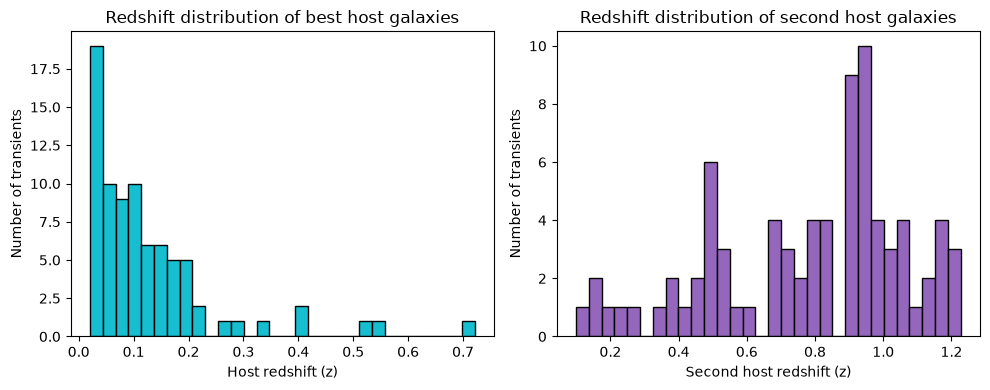

In [106]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
plt.grid()

# Primer gráfico (izquierda)
ax1.hist(z1, bins=30, color="tab:cyan", edgecolor="black")
ax1.set_title("Redshift distribution of best host galaxies")
ax1.set_xlabel("Host redshift (z)")
ax1.set_ylabel("Number of transients")
plt.grid()

# Segundo gráfico (derecha)
ax2.hist(z2, bins=30, color="tab:purple", edgecolor="black")
ax2.set_title("Redshift distribution of second host galaxies")
ax2.set_xlabel("Second host redshift (z)")
ax2.set_ylabel("Number of transients")
plt.grid()


# Ajustar espacio y mostrar
plt.grid()
plt.tight_layout()
plt.show()

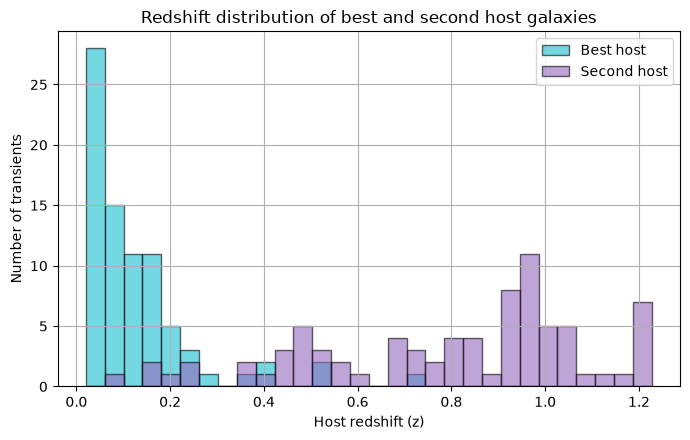

In [102]:
# Best host vs second host, same bins
bins = np.linspace(min(z1.min(), z2.min()), max(z1.max(), z2.max()), 31)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(z1, bins=bins, alpha=0.6, label="Best host", color="tab:cyan", edgecolor="black")
ax.hist(z2, bins=bins, alpha=0.6, label="Second host", color="tab:purple", edgecolor="black")
ax.set_title("Redshift distribution of best and second host galaxies")
ax.set_xlabel("Host redshift (z)")
ax.set_ylabel("Number of transients")
ax.legend()
plt.tight_layout()
plt.grid()
plt.show()

Total: 127
Host 1 with z: 80 | Host 2 with z: 80
Both with redshift(z) (considerable for the difference): 80


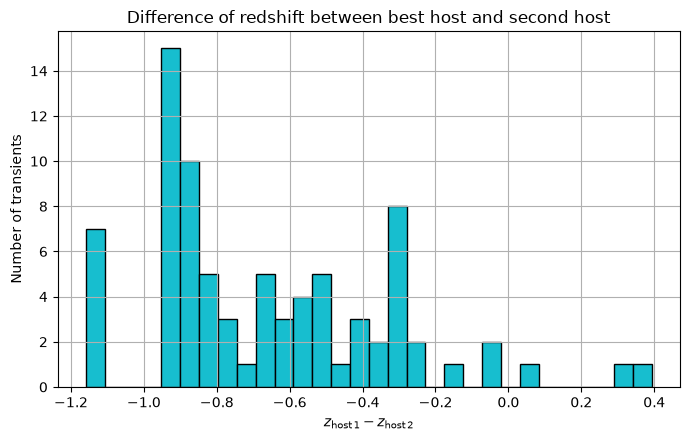

In [107]:
# 1) Ceros (y negativos) -> NaN
z1 = pd.to_numeric(hosts["host_redshift_mean"], errors="coerce")
z2 = pd.to_numeric(hosts["host_2_redshift_mean"], errors="coerce")
z1 = z1.where(z1 > 0)
z2 = z2.where(z2 > 0)

# 2) How many of them have data
both = z1.notna() & z2.notna()
print(f"Total: {len(hosts)}")
print(f"Host 1 with z: {z1.notna().sum()} | Host 2 with z: {z2.notna().sum()}")
print(f"Both with redshift(z) (considerable for the difference): {both.sum()}")

# 3) Difference
dz = (z1 - z2)[both]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(dz, bins=30, color="tab:cyan", edgecolor="black")
#ax.axvline(0, color="k", ls="--", lw=1)
ax.set_xlabel(r"$z_{\rm host\,1} - z_{\rm host\,2}$")
ax.set_ylabel("Number of transients")
ax.set_title("Difference of redshift between best host and second host")
plt.tight_layout()
plt.grid()
plt.show()

Duplicated transients: 26
Duplicated hosts:      26
Pares usables: 214 de 261


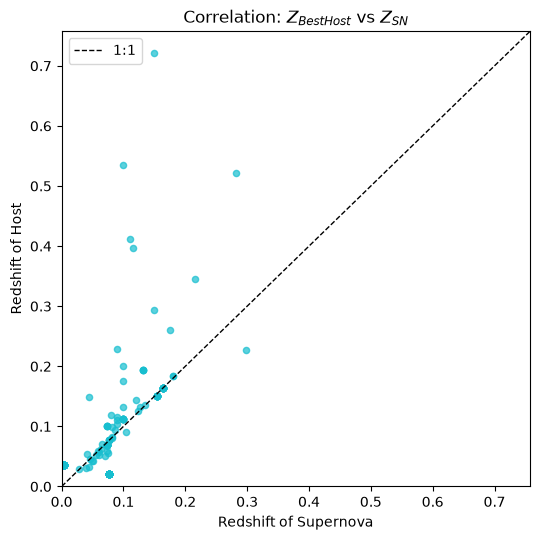

In [113]:

# 1) pair by TNS name
a = transientsog[["tns_name", "z"]].copy()
b = hosts[["tns_name", "host_redshift_mean"]].copy()
a["tns_name"] = a["tns_name"].astype(str)
b["tns_name"] = b["tns_name"].astype(str)

# Avoid duplicated rows
print("Duplicated transients:", a["tns_name"].duplicated().sum())
print("Duplicated hosts:     ", b["tns_name"].duplicated().sum())

df = a.merge(b, on="tns_name", how="inner")

# 2) Clean: valores no numéricos, ceros y negativos -> NaN
df["z"] = pd.to_numeric(df["z"], errors="coerce").where(lambda s: s > 0)
df["host_redshift_mean"] = pd.to_numeric(df["host_redshift_mean"], errors="coerce").where(lambda s: s > 0)

n_total = len(df)
df = df.dropna(subset=["z", "host_redshift_mean"])
print(f"Pares usables: {len(df)} de {n_total}")

x = df["z"]                      # redshift del transiente
y = df["host_redshift_mean"]     # redshift del host

# 3) Correlation
pearson_r, pearson_p = stats.pearsonr(x, y)
spearman_r, spearman_p = stats.spearmanr(x, y)
#print(f"Pearson  r = {pearson_r:.4f} (p = {pearson_p:.2e})")
#print(f"Spearman ρ = {spearman_r:.4f} (p = {spearman_p:.2e})")

# 4) Dispersión con línea 1:1
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(x, y, s=20, alpha=0.7, color="tab:cyan")
lim = [0, max(x.max(), y.max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1, label="1:1")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Redshift of Supernova")
ax.set_ylabel("Redshift of Host")
ax.set_title("Correlation: $Z_{Best Host}$ vs $Z_{SN}$")
ax.legend()
plt.tight_layout()
plt.show()

n = 214
Mediana (sesgo): -0.0026
NMAD (dispersión): 0.0528
Media: 0.0024 | Desv. estándar: 0.0644


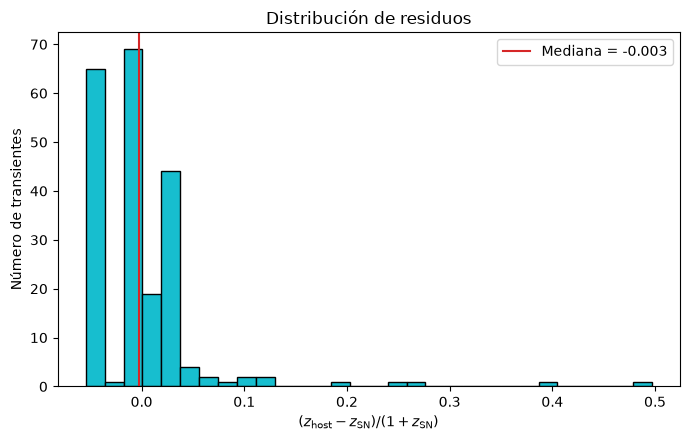

In [112]:
# residual
res = y - x
res_normal = ( y - x )/( 1 + x )

#statistical
med = res_normal.median()
nmad = 1.4826 * np.median(np.abs(res_normal - med))
print(f"n = {len(res_normal)}")
print(f"Mediana (sesgo): {med:.4f}")
print(f"NMAD (dispersión): {nmad:.4f}")
print(f"Media: {res_normal.mean():.4f} | Desv. estándar: {res_normal.std():.4f}")

# Histograma
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(res_normal, bins=30, color="tab:cyan", edgecolor="black")
#ax.axvline(0, color="k", ls="--", lw=1, label="Residuo = 0")
ax.axvline(med, color="tab:red", ls="-", lw=1.5, label=f"Mediana = {med:.3f}")
ax.set_xlabel(r"$(z_{\rm host} - z_{\rm SN}) / (1 + z_{\rm SN})$")
ax.set_ylabel("Número de transientes")
ax.set_title("Distribución de residuos")
ax.legend()
plt.tight_layout()
plt.show()

In [29]:
hosts.columns

Index(['diaObjectId', 'tns_name', 'ra', 'dec', 'idx', 'best_cat',
       'best_cat_release', 'query_time', 'smallcone_posterior',
       'missedcat_posterior', 'extra_cat_cols', 'host_objID', 'host_name',
       'host_total_posterior', 'host_ra', 'host_dec', 'host_redshift_mean',
       'host_redshift_std', 'host_redshift_info', 'host_absmag_mean',
       'host_absmag_std', 'host_absmag_info', 'host_offset_mean',
       'host_offset_std', 'host_offset_info', 'host_offset_posterior',
       'host_2_objID', 'host_2_name', 'host_2_total_posterior', 'host_2_ra',
       'host_2_dec', 'host_2_redshift_mean', 'host_2_redshift_std',
       'host_2_redshift_info', 'host_2_absmag_mean', 'host_2_absmag_std',
       'host_2_absmag_info', 'host_2_offset_mean', 'host_2_offset_std',
       'host_2_offset_info', 'host_2_offset_posterior', 'any_posterior',
       'none_posterior'],
      dtype='str')

In [42]:
# absolute magnitude histogram

# make sure values are numeric and drop NaNs
absmag1 = pd.to_numeric(hosts["host_absmag_mean"], errors="coerce").dropna()
absmag2 = pd.to_numeric(hosts["host_2_absmag_mean"], errors="coerce").dropna()

print(f"Best host:   {len(absmag1)} values, range {absmag1.min():.3f} to {absmag1.max():.3f}")
print(f"Second host: {len(absmag2)} values, range {absmag2.min():.3f} to {absmag2.max():.3f}")

Best host:   126 values, range -22.785 to 0.000
Second host: 126 values, range -21.976 to 0.000


In [44]:
absmag1

0     -20.285493
1     -20.861277
2     -20.102305
3     -19.278524
4     -22.344683
         ...    
122     0.000000
123     0.000000
124     0.000000
125     0.000000
126     0.000000
Name: host_absmag_mean, Length: 126, dtype: float64

NameError: name 'absmag11' is not defined

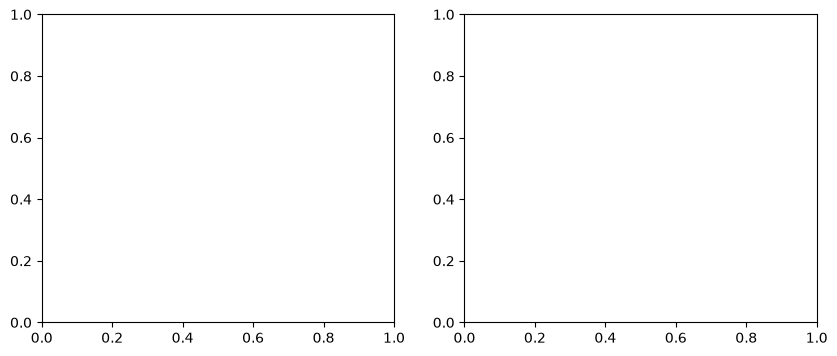

In [43]:
# Crear 1 fila y 2 columnas de gráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Primer gráfico (izquierda)
ax1.hist(absmag11, bins=30, color="tab:blue", edgecolor="white")
ax1.set_title("Redshift distribution of best host galaxies")
ax1.set_xlabel("Host redshift (z)")
ax1.set_ylabel("Number of transients")

# Segundo gráfico (derecha)
ax2.hist(absmag2, bins=30, color="tab:red", edgecolor="white")
ax2.set_title("Redshift distribution of second host galaxies")
ax2.set_xlabel("Second host redshift (z)")
ax2.set_ylabel("Number of transients")

# Ajustar espacio y mostrar
plt.tight_layout()
plt.show()